# Time-Series Machine Learning for Absolute Beginners

Welcome! This notebook teaches you how to **forecast** (predict the future from the past) using Python, scikit-learn and pmdarima. You do not need any prior machine-learning knowledge. Basic Python (variables, lists, functions, `for` loops) is enough.

## How every section works
Each section has three parts, always in this order:

1. **📖 Lesson** - explanations plus *worked examples* you simply run and read. Comments (`# ...`) in the code explain each line.
2. **✏️ Fill in the blanks** - a short code cell with `____` gaps. Replace every `____` with the right code, run the cell, and compare with the **Expected output** shown underneath. A collapsed "Stuck?" box lists the answers.
3. **🏋️ Solo exercise** - a bigger task on a *different* dataset, with only starter comments. Try it alone first. A collapsed solution and the expected results are underneath for checking.

## Sections
| # | Topic |
|---|-------|
| 0 | Setup and the datasets |
| 1 | Time series and pandas |
| 2 | Seeing patterns: trend, seasonality, noise |
| 3 | Train/test splits, baselines and error metrics |
| 4 | Features: lags, rolling windows, and avoiding leakage |
| 5 | Your first scikit-learn models |
| 6 | Time-aware cross-validation |
| 7 | ARIMA forecasting with pmdarima |
| 8 | Wrap-up and cheat sheet |

**Tips:** Run cells from top to bottom. If you restart the kernel, re-run from the top. Unfilled blanks (`____`) will cause an error such as `NameError`; that is expected until you fill them in. Because all data is generated with fixed random seeds, your numbers should match the expected outputs (the very last decimal digit could differ across computers).

---
# Section 0 - Setup and the datasets

## 📖 Lesson

Select the `ml` kernel in VS Code (top right of the notebook). The cell below imports the libraries we need:

| Library | What we use it for |
|---|---|
| `numpy` | fast maths on arrays of numbers |
| `pandas` | tables (`DataFrame`) and dates |
| `matplotlib` | drawing charts |
| `scikit-learn` (`sklearn`) | machine-learning models, metrics, cross-validation |
| `statsmodels` | decomposition and statistical tests |
| `pmdarima` | automatic ARIMA forecasting |

We also **generate fake ("dummy") datasets**. Real data is messy and sometimes confidential; fake data lets us know the true patterns, so we can see whether a model finds them.

| File | Rows | Used for |
|---|---|---|
| `coffee_sales.csv` | 730 days | lessons in sections 1-6: cups of coffee sold per day, plus that day's temperature |
| `monthly_visitors.csv` | 120 months | lesson in section 7: visitors to a museum each month |
| `bike_rentals.csv` | 547 days | solo exercises in sections 1-6 |
| `monthly_ice_cream.csv` | 96 months | solo exercise in section 7 |

`np.random.default_rng(seed)` creates a random number generator. Using the same **seed** gives the same "random" numbers every time, so results are reproducible.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pmdarima as pm
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.tsa.stattools import adfuller

from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams["figure.figsize"] = (11, 3.5)   # default chart size


def make_coffee_sales(seed=7):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2022-01-01", periods=730, freq="D")
    t = np.arange(len(dates))
    temperature = 14 + 11 * np.sin(2 * np.pi * (t - 110) / 365.25) + rng.normal(0, 2.5, len(t))
    weekend = (dates.dayofweek >= 5).astype(int)
    cups = 110 + 0.04 * t + 25 * weekend + 1.5 * (15 - temperature) + rng.normal(0, 7, len(t))
    return pd.DataFrame({"date": dates, "temperature_c": temperature.round(1),
                         "cups_sold": cups.round().astype(int)})


def make_monthly_visitors(seed=11):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2014-01-01", periods=120, freq="MS")
    t = np.arange(len(dates))
    visitors = 1000 + 7 * t + 180 * np.sin(2 * np.pi * (t - 3) / 12) + rng.normal(0, 30, len(t))
    return pd.DataFrame({"date": dates, "visitors": visitors.round().astype(int)})


def make_bike_rentals(seed=21):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2023-01-01", periods=547, freq="D")
    t = np.arange(len(dates))
    temperature = 16 + 10 * np.sin(2 * np.pi * (t - 100) / 365.25) + rng.normal(0, 2.0, len(t))
    weekend = (dates.dayofweek >= 5).astype(int)
    rentals = 250 + 0.25 * t + 70 * weekend + 9 * temperature + rng.normal(0, 30, len(t))
    return pd.DataFrame({"date": dates, "temperature_c": temperature.round(1),
                         "rentals": rentals.round().astype(int)})


def make_monthly_ice_cream(seed=5):
    rng = np.random.default_rng(seed)
    dates = pd.date_range("2016-01-01", periods=96, freq="MS")
    t = np.arange(len(dates))
    sales = 500 + 3 * t + 300 * np.sin(2 * np.pi * (t - 3) / 12) + rng.normal(0, 35, len(t))
    return pd.DataFrame({"date": dates, "tubs_sold": sales.round().astype(int)})


# Save each dataset as a CSV file in a "datasets" folder next to this notebook.
Path("datasets").mkdir(exist_ok=True)
make_coffee_sales().to_csv("datasets/coffee_sales.csv", index=False)
make_monthly_visitors().to_csv("datasets/monthly_visitors.csv", index=False)
make_bike_rentals().to_csv("datasets/bike_rentals.csv", index=False)
make_monthly_ice_cream().to_csv("datasets/monthly_ice_cream.csv", index=False)
print("Saved:", sorted(p.name for p in Path("datasets").glob("*.csv")))

Saved: ['bike_rentals.csv', 'coffee_sales.csv', 'monthly_ice_cream.csv', 'monthly_visitors.csv']


---
# Section 1 - Time series and pandas

## 📖 Lesson

A **time series** is a list of measurements taken in time order, usually at regular steps: one per day, per hour, per month. The order matters. The sales on Tuesday are related to the sales on Monday. This is different from a typical table of unrelated rows (say, a list of students), and it changes how we must do machine learning. We will see why in later sections.

**Forecasting** means predicting future values using only information that is available *at the time you make the prediction*.

### pandas in 60 seconds
* A `DataFrame` is a table: rows and columns. A single column is a `Series`.
* `pd.read_csv("file.csv", parse_dates=["date"])` loads a CSV and converts the `date` text into real date objects.
* `df.set_index("date")` makes the dates the row labels (the **index**). A time series is easiest to handle with a *date index*.
* `df.head()` shows the first rows. `df.shape` is `(rows, columns)`. `df.info()` lists column types.
* `df.loc["2022-03"]` selects by label (here: all of March 2022). `df.iloc[0]` selects by position (the first row). Remember: **`loc` = label, `iloc` = position**. Using `df.loc[0]` on a date index fails with `KeyError: 0`, because there is no row *labelled* 0.

Run the worked example below and read the comments.

In [2]:
# Load the CSV. parse_dates turns the "date" column from text into datetimes.
coffee = pd.read_csv("datasets/coffee_sales.csv", parse_dates=["date"])
print(coffee.head(3))          # look at the first three rows

# Make the date the index (row label).
coffee = coffee.set_index("date")
print("\nShape (rows, columns):", coffee.shape)
print("Index type:", type(coffee.index).__name__)

# Select by label: all of January 2022 (31 days).
january = coffee.loc["2022-01"]
print("January rows:", len(january))

# Select by position: the very first row.
print("\nFirst row:\n", coffee.iloc[0])

        date  temperature_c  cups_sold
0 2022-01-01            3.6        144
1 2022-01-02            4.3        148
2 2022-01-03            2.8        129

Shape (rows, columns): (730, 2)
Index type: DatetimeIndex
January rows: 31

First row:
 temperature_c      3.6
cups_sold        144.0
Name: 2022-01-01 00:00:00, dtype: float64


Checking that your dates are **regular** (no missing or duplicated days) is an important habit, because lag features (section 4) assume one row = one time step.

In [3]:
# Build the calendar we *expect* and compare it with the index we have.
expected_days = pd.date_range(coffee.index.min(), periods=len(coffee), freq="D")
print("Index is complete and regular:", coffee.index.equals(expected_days))
print("Missing values per column:")
print(coffee.isna().sum())

Index is complete and regular: True
Missing values per column:
temperature_c    0
cups_sold        0
dtype: int64


## ✏️ Fill in the blanks - Section 1

Replace each `____`. Hints: `.shape`, `.min()`, `.mean()`, `.idxmax()` (the label of the largest value).

In [7]:
practice = pd.read_csv("datasets/coffee_sales.csv", parse_dates=["date"])
practice = practice.set_index("date")

print("Rows and columns:", practice.shape)
print("First date:", practice.index.min().date())
print("Last date:", practice.index.max().date())
print("Average cups per day:", round(practice["cups_sold"].mean(), 1))
print("Busiest day:", practice["cups_sold"].idxmax().date())
print("Cups sold on 2022-07-04:", practice.loc["2022-07-04"]["cups_sold"])

Rows and columns: (730, 2)
First date: 2022-01-01
Last date: 2023-12-31
Average cups per day: 133.6
Busiest day: 2023-01-07
Cups sold on 2022-07-04: 106.0


**Expected output**

```text
Rows and columns: (730, 2)
First date: 2022-01-01
Last date: 2023-12-31
Average cups per day: 133.6
Busiest day: 2023-01-07
Cups sold on 2022-07-04: 106
```

<details><summary>Stuck? Show the answers (in order of the blanks)</summary>

1. `parse_dates=["date"]`
2. `set_index("date")`
3. `shape`
4. `min()`
5. `mean()`
6. `idxmax()`
7. `loc["2022-07-04", "cups_sold"]`

</details>

## 🏋️ Solo exercise - Section 1: bike rentals

Dataset: `datasets/bike_rentals.csv` (columns `date`, `temperature_c`, `rentals`; one row per day).

1. Load the CSV into a DataFrame called `bikes`, parsing the `date` column, and set `date` as the index.
2. Print its shape and the first and last dates.
3. Check the index is complete and regular (no missing days) and print the number of missing values in the whole table.
4. Print the average rentals on **weekdays** and on **weekends**. (Hint: `bikes.index.dayofweek` is 0 for Monday ... 6 for Sunday, so weekends are `>= 5`.)
5. Print the date and value of the day with the most rentals.
6. Plot `rentals` over time with a title and y-axis label.

In [10]:
# YOUR CODE HERE
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"])
bikes = bikes.set_index("date")

print("Shape:", bikes.shape)
print("First date:", bikes.index.min().date())
print("Last date:", bikes.index.max().date())
bikes_expected_days = pd.date_range(bikes.index.min(), periods=len(bikes), freq="D")
print("Index complete and regular:", bikes.index.equals(bikes_expected_days))

is_weekend = bikes.index.dayofweek >= 5
print("Average weekday rentals:", round(bikes.loc[~is_weekend, "rentals"].mean(), 1))
print("Average weekday rentals:", round(bikes.loc[is_weekend, "rentals"].mean(), 1))
best_bikes = bikes["rentals"].idxmax()
print(f"Best day: {best_bikes} with {bikes.loc[best_bikes]["rentals"]} rentals")

Shape: (547, 2)
First date: 2023-01-01
Last date: 2024-06-30
Index complete and regular: True
Average weekday rentals: 461.8
Average weekday rentals: 529.1
Best day: 2024-06-15 00:00:00 with 741.0 rentals


**Expected results** (your numbers should match; charts are not shown)

```text
Shape: (547, 2)
First date: 2023-01-01 | Last date: 2024-06-30
Index complete and regular: True
Total missing values: 0
Average weekday rentals: 461.8
Average weekend rentals: 529.1
Best day: 2024-06-15 with 741 rentals
```

<details><summary>Show a sample solution (try it yourself first!)</summary>

```python
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"]).set_index("date")
print("Shape:", bikes.shape)
print("First date:", bikes.index.min().date(), "| Last date:", bikes.index.max().date())

complete = bikes.index.equals(pd.date_range(bikes.index.min(), periods=len(bikes), freq="D"))
print("Index complete and regular:", complete)
print("Total missing values:", int(bikes.isna().sum().sum()))

is_weekend = bikes.index.dayofweek >= 5
print("Average weekday rentals:", round(bikes.loc[~is_weekend, "rentals"].mean(), 1))
print("Average weekend rentals:", round(bikes.loc[is_weekend, "rentals"].mean(), 1))

best_day = bikes["rentals"].idxmax()
print("Best day:", best_day.date(), "with", bikes.loc[best_day, "rentals"], "rentals")

ax = bikes["rentals"].plot(title="Daily bike rentals")
ax.set_ylabel("Rentals")
plt.show()
```

</details>

---
# Section 2 - Seeing patterns: trend, seasonality, noise

## 📖 Lesson

Before modelling, *look at the data*. Most time series are a mix of:

* **Trend** - slow, long-term rise or fall (e.g. a growing business).
* **Seasonality** - a pattern that repeats at a fixed period: every 7 days (weekly) or every 12 months (yearly). The length of one cycle is the **period**.
* **Noise** - random ups and downs we cannot predict.

Three tools, all in pandas:

* `resample("W").mean()` - **aggregate** to a coarser frequency (daily -> weekly). Codes: `"W"` week, `"MS"` month start.
* `rolling(window).mean()` - a **moving average**: each point becomes the average of itself and the previous `window - 1` points. It smooths noise so the trend is visible. The first `window - 1` values are `NaN` ("not a number" = missing) because there isn't enough history yet.
* `groupby(index.dayofweek).mean()` - average by weekday, which exposes weekly seasonality.

`seasonal_decompose` from statsmodels separates a series into trend + seasonal + residual (noise) parts automatically.

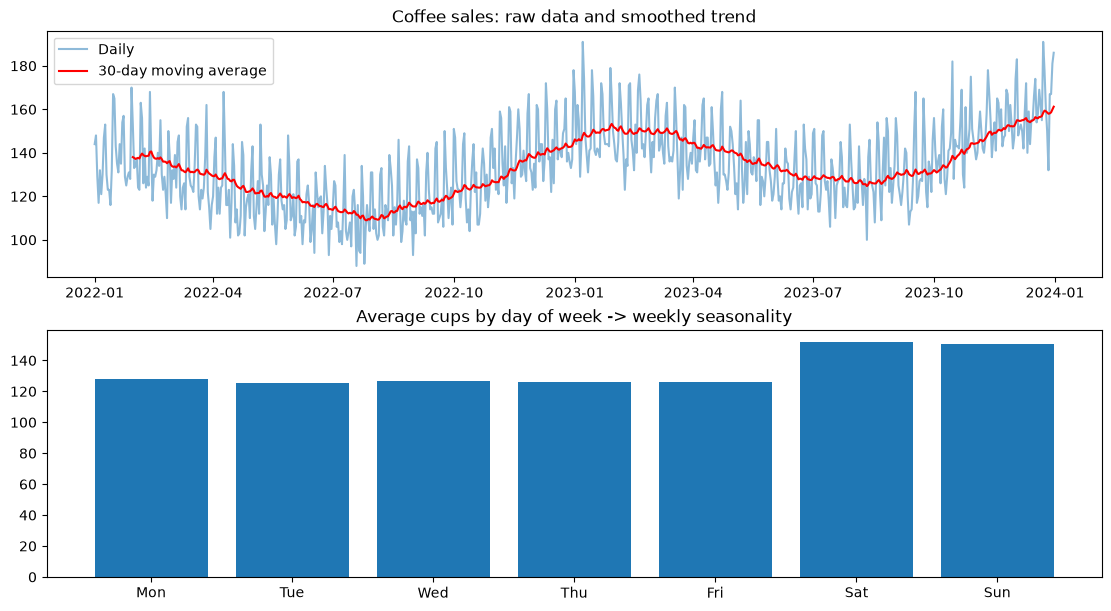

date
0    128.0
1    125.3
2    126.4
3    126.3
4    125.9
5    151.8
6    150.9
Name: cups_sold, dtype: float64


In [11]:
cups = coffee["cups_sold"]

fig, axes = plt.subplots(2, 1, figsize=(11, 6), constrained_layout=True)
axes[0].plot(cups, alpha=0.5, label="Daily")
axes[0].plot(cups.rolling(30).mean(), color="red", label="30-day moving average")
axes[0].set_title("Coffee sales: raw data and smoothed trend")
axes[0].legend()

# Average cups for each day of the week (0 = Monday ... 6 = Sunday).
weekday_means = cups.groupby(cups.index.dayofweek).mean()
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], weekday_means)
axes[1].set_title("Average cups by day of week -> weekly seasonality")
plt.show()

print(weekday_means.round(1))

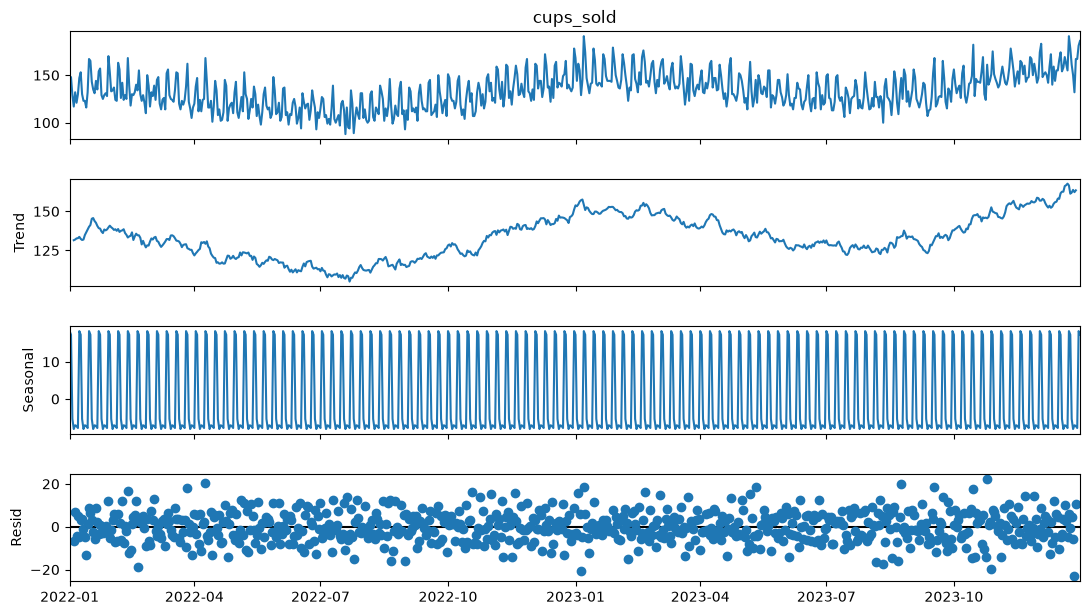

In [12]:
# Decompose into trend, seasonal and residual parts. period=7 means weekly cycles.
parts = seasonal_decompose(cups, model="additive", period=7)
fig = parts.plot()
fig.set_size_inches(11, 7)
plt.show()

Reading the picture: the *trend* panel rises and falls through the year (temperature effect) with a slight upward slope, the *seasonal* panel is a repeating 7-day shape with weekends higher, and the *residual* panel is what's left over (noise).

## ✏️ Fill in the blanks - Section 2

Hints: `resample("W")`, `rolling(30)`, and `dayofweek`.

In [14]:
weekly = coffee["cups_sold"].resample("W").mean()
print("Number of weekly values:", len(weekly))

rolling_30 = coffee["cups_sold"].rolling(30).mean()
print("NaNs at the start of the rolling mean:", int(rolling_30.isna().sum()))

by_day = coffee.groupby(coffee.index.dayofweek)["cups_sold"].mean().round(1)
print("Best weekday number (0=Mon):", by_day.idxmax())
print(by_day)

Number of weekly values: 105
NaNs at the start of the rolling mean: 29
Best weekday number (0=Mon): 5
date
0    128.0
1    125.3
2    126.4
3    126.3
4    125.9
5    151.8
6    150.9
Name: cups_sold, dtype: float64


**Expected output**

```text
Number of weekly values: 105
NaNs at the start of the rolling mean: 29
Best weekday number (0=Mon): 5
date
0    128.0
1    125.3
2    126.4
3    126.3
4    125.9
5    151.8
6    150.9
Name: cups_sold, dtype: float64
```

<details><summary>Stuck? Show the answers (in order of the blanks)</summary>

1. `resample("W")`
2. `rolling(30)`
3. `isna()`
4. `dayofweek`
5. `idxmax()`

</details>

## 🏋️ Solo exercise - Section 2: bike patterns

Using the `bikes` DataFrame from the Section 1 exercise (reload it if needed):

1. Create `weekly` (weekly mean of `rentals`) and `monthly` (monthly mean using `"MS"`). Print how many values each has.
2. Create a 30-day moving average of `rentals` and print how many `NaN` values it contains.
3. Make one chart with the daily data and the 30-day moving average drawn on top.
4. Print the average rentals for each day of the week (0-6), rounded to 1 decimal place.
5. Print the month (as `YYYY-MM`) with the highest average rentals.
6. Run `seasonal_decompose(..., period=7)` and plot it.
7. In a Markdown cell, write two sentences describing the trend and the seasonality you see.

Weekly length: 79, Monthly length: 18
NaNs in rolling mean: 29
date
0    459.5
1    468.8
2    460.3
3    456.4
4    464.3
5    527.7
6    530.4
Name: rentals, dtype: float64
Highest month: 2024-06


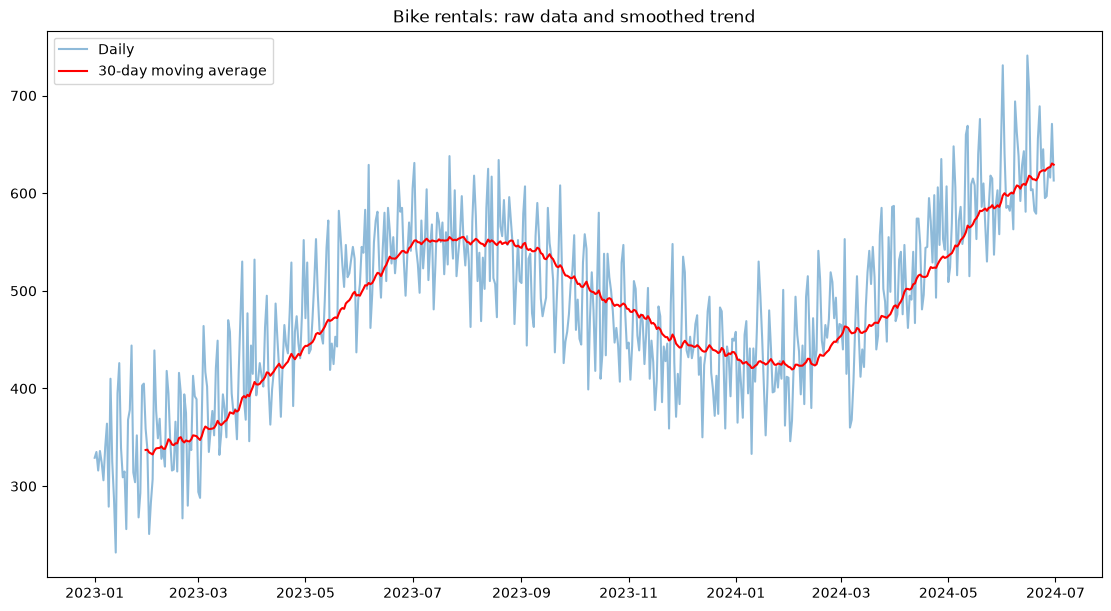

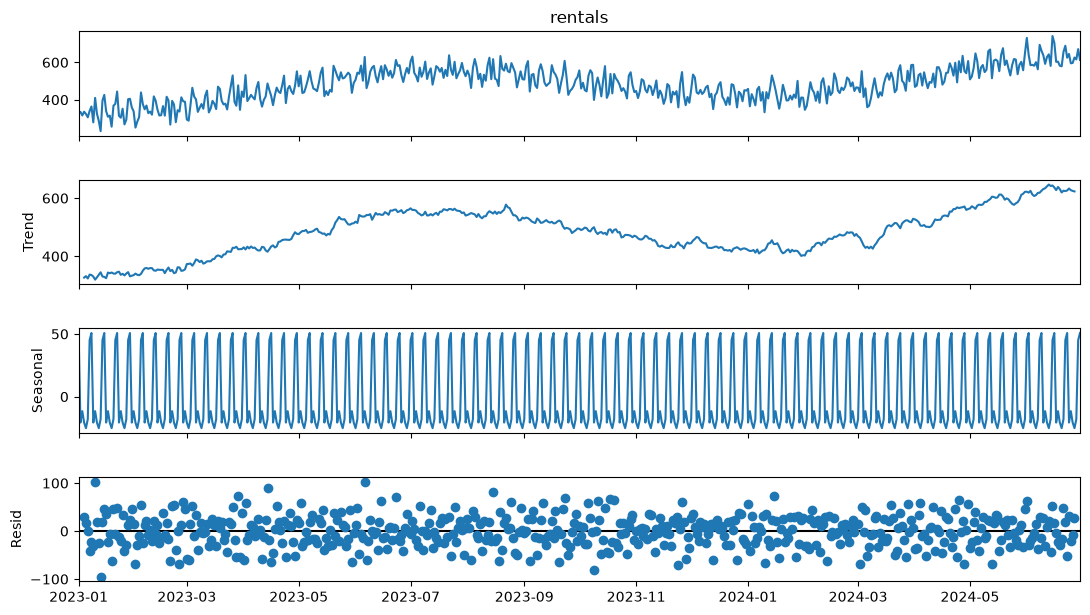

In [20]:
# YOUR CODE HERE
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"])
bikes = bikes.set_index("date")

weekly = bikes["rentals"].resample("W").mean()
monthly = bikes["rentals"].resample("MS").mean()
print(f"Weekly length: {len(weekly)}, Monthly length: {len(monthly)}")

rolling_30 = bikes["rentals"].rolling(30).mean()
print("NaNs in rolling mean:", int(rolling_30.isna().sum()))

rentals = bikes["rentals"]

fig, ax = plt.subplots(1, figsize=(11, 6), constrained_layout=True)
ax.plot(rentals, alpha=0.5, label="Daily")
ax.plot(rentals.rolling(30).mean(), color="red", label="30-day moving average")
ax.set_title("Bike rentals: raw data and smoothed trend")
ax.legend()

by_day = bikes.groupby(bikes.index.dayofweek)["rentals"].mean().round(1)
print(by_day)

print("Highest month:", monthly.idxmax().strftime("%Y-%m"))

parts = seasonal_decompose(rentals, model="additive", period=7)
fig = parts.plot()
fig.set_size_inches(11, 7)
plt.show()

**Expected results** (your numbers should match; charts are not shown)

```text
Weekly values: 79 | Monthly values: 18
NaNs in rolling mean: 29
date
0    459.5
1    468.8
2    460.3
3    456.4
4    464.3
5    527.7
6    530.4
Name: rentals, dtype: float64
Highest month: 2024-06
```

<details><summary>Show a sample solution (try it yourself first!)</summary>

```python
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"]).set_index("date")
rentals = bikes["rentals"]

weekly = rentals.resample("W").mean()
monthly = rentals.resample("MS").mean()
print("Weekly values:", len(weekly), "| Monthly values:", len(monthly))

rolling_30 = rentals.rolling(30).mean()
print("NaNs in rolling mean:", int(rolling_30.isna().sum()))

ax = rentals.plot(alpha=0.5, label="Daily", title="Bike rentals with 30-day average")
rolling_30.plot(ax=ax, color="red", label="30-day average")
ax.legend()
plt.show()

print(rentals.groupby(rentals.index.dayofweek).mean().round(1))
print("Highest month:", monthly.idxmax().strftime("%Y-%m"))

seasonal_decompose(rentals, model="additive", period=7).plot()
plt.show()
# Trend: rentals rise in summer and fall in winter on top of a slow upward drift.
# Seasonality: a 7-day cycle with clearly higher rentals on weekends.
```

</details>

---
# Section 3 - Train/test splits, baselines and error metrics

## 📖 Lesson

### Why we never shuffle time-series data
In ordinary machine learning we randomly split rows into *training* and *test* sets. For a time series that would let the model "peek" at the future: it could learn from Wednesday and Friday, then be tested on Thursday. Real forecasting never gets that advantage. So we split **chronologically**: the **train** set is the earlier part, the **test** set is the latest part, which the model never sees while learning.

### Baselines: the bar to beat
A **baseline** is a very simple forecast. If a complicated model cannot beat it, the model isn't worth using.
* **Persistence (naive)**: predict that today equals yesterday: `series.shift(1)`.
* **Seasonal naive**: predict that today equals the same weekday last week: `series.shift(7)`.

`shift(k)` slides values down by `k` rows, so each row sees the value from `k` steps *earlier*.

### Error metrics
Let *error = actual - predicted*.
* **MAE** (mean absolute error) = average of `|error|`. Easy to read: "we are off by about X cups on average".
* **RMSE** (root mean squared error) = `sqrt(average(error²))`. Penalises big mistakes more.
* Lower is better for both, and both are in the same units as the data.

A note on how we evaluate: here each test day is predicted with the *actual* values of previous days (they arrive daily). That is a **one-step-ahead** forecast.

In [21]:
cups = coffee["cups_sold"]
test_days = 60

train_cups = cups.iloc[:-test_days]      # everything except the last 60 days
test_cups = cups.iloc[-test_days:]       # the last 60 days
print("Train:", train_cups.index.min().date(), "to", train_cups.index.max().date(), f"({len(train_cups)} days)")
print("Test: ", test_cups.index.min().date(), "to", test_cups.index.max().date(), f"({len(test_cups)} days)")
assert train_cups.index.max() < test_cups.index.min()   # train must come BEFORE test

# Baseline predictions for the test days.
persistence = cups.shift(1).loc[test_cups.index]    # yesterday's value
seasonal_naive = cups.shift(7).loc[test_cups.index] # same weekday last week

def report(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f"{name:<16} MAE = {mae:6.2f}   RMSE = {rmse:6.2f}")

report("Persistence", test_cups, persistence)
report("Seasonal naive", test_cups, seasonal_naive)

Train: 2022-01-01 to 2023-11-01 (670 days)
Test:  2023-11-02 to 2023-12-31 (60 days)
Persistence      MAE =  11.83   RMSE =  14.60
Seasonal naive   MAE =   8.52   RMSE =  11.24


Seasonal naive wins easily because weekends really are different from weekdays: copying yesterday gets every Monday and Saturday wrong. These two numbers are now the **bar every later model must beat**.

## ✏️ Fill in the blanks - Section 3

Compute the seasonal-naive MAE and RMSE *by hand* (without scikit-learn) and compare with scikit-learn's answer.

In [23]:
test_days = 60
train_part = coffee["cups_sold"].iloc[:-test_days]
test_part = coffee["cups_sold"].iloc[-test_days:]
print("Train length:", len(train_part), "| Test length:", len(test_part))

predicted = coffee["cups_sold"].shift(7).loc[test_part.index]
errors = test_part - predicted

mae_by_hand = errors.abs().mean()
rmse_by_hand = np.sqrt((errors ** 2).mean())
print("MAE by hand: ", round(mae_by_hand, 3))
print("RMSE by hand:", round(rmse_by_hand, 3))

print("MAE sklearn: ", round(mean_absolute_error(test_part, predicted), 3))

Train length: 670 | Test length: 60
MAE by hand:  8.517
RMSE by hand: 11.244
MAE sklearn:  8.517


**Expected output**

```text
Train length: 670 | Test length: 60
MAE by hand:  8.517
RMSE by hand: 11.244
MAE sklearn:  8.517
```

<details><summary>Stuck? Show the answers (in order of the blanks)</summary>

1. `iloc[:-test_days]`
2. `iloc[-test_days:]`
3. `shift(7)`
4. `abs()`
5. `mean()`
6. `mean_absolute_error(test_part, predicted)`

</details>

## 🏋️ Solo exercise - Section 3: bike baselines

Reload `bikes` if needed. Series of interest: `bikes["rentals"]`.

1. Hold out the **last 90 days** as the test set. Print the train/test date ranges and lengths, and `assert` that train ends before test starts.
2. Build the two baselines for the test days: persistence (`shift(1)`) and seasonal naive (`shift(7)`).
3. Write a small function `report(name, actual, predicted)` that prints MAE and RMSE (use scikit-learn).
4. Print both baselines' results, then print which baseline is better by MAE.
5. Plot the actual test values and the seasonal-naive prediction on one chart.
6. **Think:** if the data were instead shuffled before splitting, why would the MAE look unrealistically good?

Train: 2023-01-01 to 2024-04-01 (457 days)
Test:  2024-04-02 to 2024-06-30 (90 days)
Persistence      MAE =  48.71   RMSE =  60.32
Seasonal Naive   MAE =  35.93   RMSE =  45.21
Persistence      MAE =  48.71   RMSE =  60.32
Seasonal Naive   MAE =  35.93   RMSE =  45.21
Better baseline: Seasonal Naive


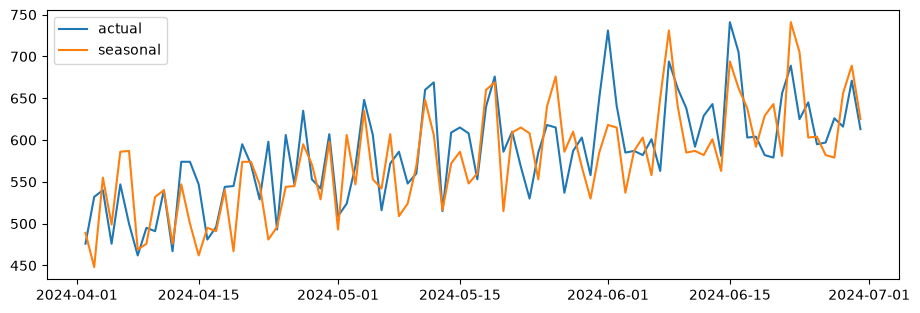

In [27]:
# YOUR CODE HERE
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"])
bikes = bikes.set_index("date")

rentals = bikes["rentals"]

test_days = 90
train = rentals.iloc[:-test_days]
test = rentals.iloc[-test_days:]
print("Train:", train.index.min().date(), "to", train.index.max().date(), f"({len(train)} days)")
print("Test: ", test.index.min().date(), "to", test.index.max().date(), f"({len(test)} days)")
assert train.index.max() < test.index.min()

persistence = rentals.shift(1).loc[test.index]
seasonal_naive = rentals.shift(7).loc[test.index]

def report(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f"{name:<16} MAE = {mae:6.2f}   RMSE = {rmse:6.2f}")
    return [mae, rmse]

report("Persistence", test, persistence)
report("Seasonal Naive", test, seasonal_naive)

print("Better baseline: Seasonal Naive" if report("Persistence", test, persistence)[0] > report("Seasonal Naive", test, seasonal_naive)[0] else "Better baseline: Persistence")

plt.plot(test, label = "actual")
plt.plot(seasonal_naive, label = "seasonal")
plt.legend()
plt.show()

**Expected results** (your numbers should match; charts are not shown)

```text
Train: 2023-01-01 to 2024-04-01 457
Test:  2024-04-02 to 2024-06-30 90
Persistence      MAE =  48.71   RMSE =  60.32
Seasonal naive   MAE =  35.93   RMSE =  45.21
Better baseline: Seasonal naive
```

<details><summary>Show a sample solution (try it yourself first!)</summary>

```python
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"]).set_index("date")
rentals = bikes["rentals"]
test_days = 90
train_r, test_r = rentals.iloc[:-test_days], rentals.iloc[-test_days:]
print("Train:", train_r.index.min().date(), "to", train_r.index.max().date(), len(train_r))
print("Test: ", test_r.index.min().date(), "to", test_r.index.max().date(), len(test_r))
assert train_r.index.max() < test_r.index.min()

persistence = rentals.shift(1).loc[test_r.index]
seasonal = rentals.shift(7).loc[test_r.index]

def report(name, actual, predicted):
    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))
    print(f"{name:<16} MAE = {mae:6.2f}   RMSE = {rmse:6.2f}")
    return mae

mae_p = report("Persistence", test_r, persistence)
mae_s = report("Seasonal naive", test_r, seasonal)
print("Better baseline:", "Seasonal naive" if mae_s < mae_p else "Persistence")

plt.plot(test_r, label="Actual")
plt.plot(seasonal, label="Seasonal naive")
plt.legend()
plt.show()
# Shuffling lets the model train on days around each test day (including later days),
# so it can interpolate and looks far better than any real forecast could.
```

</details>

---
# Section 4 - Features: lags, rolling windows, and avoiding leakage

## 📖 Lesson

scikit-learn models predict a **target** `y` from a table of **features** `X`. A time series has just one column, so we must *create* features from its past. This is called **feature engineering**, and it turns forecasting into ordinary supervised learning.

Our target is `cups_sold`. Features we will build for day *t*:

| Feature | Meaning | Code |
|---|---|---|
| `lag_1` | cups sold yesterday | `shift(1)` |
| `lag_7` | cups sold a week ago | `shift(7)` |
| `rolling_7` | average of the previous 7 days | `shift(1).rolling(7).mean()` |
| `day_of_week` | 0-6 | `index.dayofweek` |
| `is_weekend` | 1 if Sat/Sun | `(dayofweek >= 5)` |
| `temperature_c` | the day's temperature | existing column (we assume a weather forecast is available) |

### Data leakage - the #1 mistake
**Leakage** means a feature contains information that would **not be available** when making the real prediction, for example the target itself or something from the future. Models with leakage look brilliant in testing and fail in real use.

Notice the `shift(1)` *before* `.rolling(7)`. Without it, the rolling window would include *today's* value, which is the answer we are trying to predict!

The first few rows have `NaN` features (no earlier history exists), so we remove them with `dropna()`.

**How to test for leakage:** change the data at and after a date `t`, recompute the features, and confirm the features for day `t` didn't change. If they did change, the features used information from `t` or later.

In [ ]:
feature_cols = ["day_of_week", "is_weekend", "temperature_c", "lag_1", "lag_7", "rolling_7"]


def make_features(frame, target="cups_sold"):
    out = frame.copy()
    out["day_of_week"] = out.index.dayofweek
    out["is_weekend"] = (out.index.dayofweek >= 5).astype(int)
    out["lag_1"] = out[target].shift(1)
    out["lag_7"] = out[target].shift(7)
    out["rolling_7"] = out[target].shift(1).rolling(7).mean()   # shift(1) keeps today OUT of the window
    return out.dropna()


coffee_feat = make_features(coffee)
print("Rows before:", len(coffee), "| after dropping NaN rows:", len(coffee_feat))
print(coffee_feat.head(3).round(2))

In [ ]:
# Leakage test: wreck the data from check_date onwards and recompute the features.
check_date = coffee.index[100]
changed = coffee.copy()
changed.loc[check_date:, "cups_sold"] += 1000

before = make_features(coffee).loc[check_date, feature_cols]
after = make_features(changed).loc[check_date, feature_cols]
pd.testing.assert_series_equal(before, after)   # raises an error if they differ
print("No leakage: features for", check_date.date(), "ignore today's and future cups_sold.")

# For contrast, a LEAKY feature (rolling window that includes today):
leaky = coffee["cups_sold"].rolling(7).mean()
leaky_changed = changed["cups_sold"].rolling(7).mean()
print("Leaky feature changed when today's value changed:", leaky.loc[check_date] != leaky_changed.loc[check_date])

## ✏️ Fill in the blanks - Section 4

In [ ]:
demo = coffee[["cups_sold"]].copy()
demo["lag_1"] = demo["cups_sold"].____
demo["lag_7"] = demo["cups_sold"].shift(____)
demo["rolling_7"] = demo["cups_sold"].shift(1).____.mean()
demo["day_of_week"] = demo.index.____
demo = demo.____

print("Shape:", demo.shape)
print(demo.head(3).round(2))

# Leakage check on the engineered 'lag_1' feature.
day = demo.index[50]
altered = coffee["cups_sold"].copy()
altered.loc[day:] += 500
altered_lag_1 = altered.____.loc[day]
print("lag_1 unchanged by today's value:", altered_lag_1 == demo.loc[day, "lag_1"])

**Expected output**

```text
Shape: (723, 5)
            cups_sold  lag_1  lag_7  rolling_7  day_of_week
date                                                       
2022-01-08        147  130.0  144.0     131.57            5
2022-01-09        153  147.0  148.0     132.00            6
2022-01-10        130  153.0  129.0     132.71            0
lag_1 unchanged by today's value: True
```

<details><summary>Stuck? Show the answers (in order of the blanks)</summary>

1. `shift(1)`
2. `7`
3. `rolling(7)`
4. `dayofweek`
5. `dropna()`
6. `shift(1)`

</details>

## 🏋️ Solo exercise - Section 4: bike features

Reload `bikes` if needed.

1. Write a function `make_bike_features(frame)` that returns a copy of the DataFrame with these columns added: `is_weekend`, `lag_1`, `lag_7`, `rolling_7` (mean of the *previous* 7 days, no leakage), and then drops rows with missing values. Keep the existing `temperature_c` column too.
2. Run it on `bikes`, then print the number of rows before and after, and the first 3 rows (rounded to 2 decimals).
3. Add a **28-day lag** column `lag_28` and a 28-day shifted rolling mean `rolling_28` inside the function (these remove 28 rows instead of 7). Print the new shape.
4. Write a leakage test: add 1000 to `rentals` from `bikes.index[100]` onwards, recompute, and use `pd.testing.assert_series_equal` to prove the features for that date don't change. Print a success message.
5. **Think:** why do rows at the start get dropped rather than filled with zeros?

In [ ]:
# YOUR CODE HERE

**Expected results** (your numbers should match; charts are not shown)

```text
Rows before: 547 | after: 540
            temperature_c  rentals  is_weekend  lag_1  lag_7  rolling_7
date                                                                   
2023-01-08            3.8      364           1  340.0  329.0     326.57
2023-01-09            5.6      279           0  364.0  335.0     331.57
2023-01-10            7.7      410           0  279.0  316.0     323.57
With 28-day features: (519, 8)
No leakage for 2023-04-11
```

<details><summary>Show a sample solution (try it yourself first!)</summary>

```python
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"]).set_index("date")

def make_bike_features(frame, long_windows=False):
    out = frame.copy()
    out["is_weekend"] = (out.index.dayofweek >= 5).astype(int)
    out["lag_1"] = out["rentals"].shift(1)
    out["lag_7"] = out["rentals"].shift(7)
    out["rolling_7"] = out["rentals"].shift(1).rolling(7).mean()
    if long_windows:
        out["lag_28"] = out["rentals"].shift(28)
        out["rolling_28"] = out["rentals"].shift(1).rolling(28).mean()
    return out.dropna()

basic = make_bike_features(bikes)
print("Rows before:", len(bikes), "| after:", len(basic))
print(basic.head(3).round(2))
print("With 28-day features:", make_bike_features(bikes, long_windows=True).shape)

cols = ["is_weekend", "temperature_c", "lag_1", "lag_7", "rolling_7", "lag_28", "rolling_28"]
day = bikes.index[100]
altered = bikes.copy()
altered.loc[day:, "rentals"] += 1000
a = make_bike_features(bikes, long_windows=True).loc[day, cols]
b = make_bike_features(altered, long_windows=True).loc[day, cols]
pd.testing.assert_series_equal(a, b)
print("No leakage for", day.date())
# Zero would be a fake measurement ("we sold 0 yesterday"), teaching the model false history.
```

</details>

---
# Section 5 - Your first scikit-learn models

## 📖 Lesson

Every scikit-learn model follows the same three-step pattern:

```python
model = SomeModel(settings)   # 1. create
model.fit(X_train, y_train)   # 2. learn from training data
pred = model.predict(X_test)  # 3. predict on new data
```

Models we will use:

* **Linear regression / Ridge** - draws the best straight-line (weighted-sum) relationship between features and target. Fast and easy to interpret. *Ridge* adds a small penalty (`alpha`) that keeps the weights from getting too large, which helps when features are correlated.
* **Random forest** - averages many decision trees, each asking yes/no questions such as "is `lag_7` > 130?". It captures curved and non-linear relationships. `n_estimators` is the number of trees; `random_state` makes it reproducible.
* **Pipeline with `StandardScaler`** - rescales each feature to a similar range (mean 0, spread 1). Linear models like this; trees don't need it. A *pipeline* bundles scaling + model into one object so that scaling is **learned only from training data** (otherwise test information leaks into training).

Our recipe: build features, split by time (last 60 days = test), fit on train, evaluate on test, and **compare against the seasonal-naive baseline** (which is simply the `lag_7` column).

In [ ]:
test_days = 60
train_rows = coffee_feat.iloc[:-test_days]
test_rows = coffee_feat.iloc[-test_days:]

X_train, y_train = train_rows[feature_cols], train_rows["cups_sold"]
X_test, y_test = test_rows[feature_cols], test_rows["cups_sold"]
print("Training examples:", len(X_train), "| Test examples:", len(X_test))

models = {
    "Ridge (with scaling)": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Random forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=0),
}

results = {"Seasonal naive (lag_7)": mean_absolute_error(y_test, X_test["lag_7"])}
predictions = {}
for name, model in models.items():
    model.fit(X_train, y_train)                    # learn from the past
    predictions[name] = model.predict(X_test)      # forecast the test period
    results[name] = mean_absolute_error(y_test, predictions[name])

print(pd.Series(results, name="Test MAE").round(2).sort_values())

In [ ]:
plt.figure(figsize=(11, 3.5))
plt.plot(y_test, label="Actual", linewidth=2)
plt.plot(y_test.index, predictions["Ridge (with scaling)"], label="Ridge")
plt.plot(y_test.index, predictions["Random forest"], label="Random forest", alpha=0.8)
plt.title("Last 60 days: actual vs. predicted cups sold")
plt.legend()
plt.show()

# Which features does the random forest rely on?
importance = pd.Series(models["Random forest"].feature_importances_, index=feature_cols)
print(importance.sort_values(ascending=False).round(3))

Read the table carefully: Ridge beats the seasonal-naive baseline, but the random forest does **not**. A fancier model is not automatically better, and this is exactly why we always compare against baselines. One known reason: a tree can only predict values it has seen in training (averages of training targets), so it cannot **extrapolate** a rising trend, whereas a linear model can. Feature importances show which inputs the forest used most, but they describe the *model*, not necessarily real-world cause and effect.

## ✏️ Fill in the blanks - Section 5

In [ ]:
X_tr = train_rows[feature_cols]
y_tr = train_rows["cups_sold"]
X_te = test_rows[feature_cols]
y_te = test_rows["cups_sold"]

linear = ____
linear.____
linear_pred = linear.____
print("Linear regression MAE:", round(mean_absolute_error(y_te, linear_pred), 3))

forest = RandomForestRegressor(n_estimators=50, random_state=____)
forest.fit(X_tr, y_tr)
forest_pred = forest.predict(X_te)
print("Random forest MAE:    ", round(mean_absolute_error(y_te, forest_pred), 3))

print("Learned weights for linear regression:")
print(pd.Series(linear.____, index=feature_cols).round(2))

**Expected output**

```text
Linear regression MAE: 7.382
Random forest MAE:     9.398
Learned weights for linear regression:
day_of_week      -0.40
is_weekend       27.55
temperature_c    -0.34
lag_1             0.01
lag_7            -0.03
rolling_7         0.80
dtype: float64
```

<details><summary>Stuck? Show the answers (in order of the blanks)</summary>

1. `LinearRegression()`
2. `fit(X_tr, y_tr)`
3. `predict(X_te)`
4. `0`
5. `coef_`

</details>

## 🏋️ Solo exercise - Section 5: forecast bike rentals

Use the 28-day-free version of your Section 4 features (`is_weekend`, `temperature_c`, `lag_1`, `lag_7`, `rolling_7`).

1. Build the features with your `make_bike_features` (or re-define it) and split off the **last 90 rows** as the test set.
2. Define `X_train`, `y_train`, `X_test`, `y_test` using feature columns `["is_weekend", "temperature_c", "lag_1", "lag_7", "rolling_7"]` and target `rentals`.
3. Fit three models: `LinearRegression()`, a Ridge pipeline (`StandardScaler` + `Ridge(alpha=10)`), and `RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=0)`.
4. Print each model's test MAE together with the seasonal-naive MAE (the `lag_7` column) in one table, sorted best to worst.
5. Plot the actual last 90 days and the best model's predictions.
6. Print the random forest's feature importances, sorted.
7. **Think:** is the best model clearly better than the baseline? By how much, in percentage terms? Why might the random forest do poorly on data with a rising trend?

In [ ]:
# YOUR CODE HERE

**Expected results** (your numbers should match; charts are not shown)

```text
Linear regression         29.87
Ridge (scaled)            30.63
Seasonal naive (lag_7)    35.93
Random forest             62.73
Name: Test MAE, dtype: float64
rolling_7        0.504
lag_7            0.224
temperature_c    0.141
is_weekend       0.101
lag_1            0.030
dtype: float64
Best model (Linear regression) improves on the baseline by 17%
```

<details><summary>Show a sample solution (try it yourself first!)</summary>

```python
bikes = pd.read_csv("datasets/bike_rentals.csv", parse_dates=["date"]).set_index("date")
b = bikes.copy()
b["is_weekend"] = (b.index.dayofweek >= 5).astype(int)
b["lag_1"] = b["rentals"].shift(1)
b["lag_7"] = b["rentals"].shift(7)
b["rolling_7"] = b["rentals"].shift(1).rolling(7).mean()
b = b.dropna()

bike_cols = ["is_weekend", "temperature_c", "lag_1", "lag_7", "rolling_7"]
bike_train, bike_test = b.iloc[:-90], b.iloc[-90:]
Xb_train, yb_train = bike_train[bike_cols], bike_train["rentals"]
Xb_test, yb_test = bike_test[bike_cols], bike_test["rentals"]

bike_models = {
    "Linear regression": LinearRegression(),
    "Ridge (scaled)": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=0),
}
bike_results = {"Seasonal naive (lag_7)": mean_absolute_error(yb_test, Xb_test["lag_7"])}
bike_preds = {}
for name, model in bike_models.items():
    model.fit(Xb_train, yb_train)
    bike_preds[name] = model.predict(Xb_test)
    bike_results[name] = mean_absolute_error(yb_test, bike_preds[name])

bike_table = pd.Series(bike_results, name="Test MAE").round(2).sort_values()
print(bike_table)

best = next(n for n in bike_table.index if n in bike_preds)
plt.plot(yb_test, label="Actual")
plt.plot(yb_test.index, bike_preds[best], label=best)
plt.legend()
plt.show()

print(pd.Series(bike_models["Random forest"].feature_importances_, index=bike_cols)
      .sort_values(ascending=False).round(3))
gain = 100 * (1 - bike_table[best] / bike_results["Seasonal naive (lag_7)"])
print(f"Best model ({best}) improves on the baseline by {gain:.0f}%")
```

</details>

---
# Section 6 - Time-aware cross-validation

## 📖 Lesson

One test period can be lucky or unlucky. **Cross-validation** (CV) repeats the evaluation several times to get a more reliable score. Ordinary CV shuffles rows, which breaks time order, so we use **`TimeSeriesSplit`**, an *expanding window*: 

```
Fold 1: [train.....][validate]
Fold 2: [train..........][validate]
Fold 3: [train...............][validate]
```
Each fold trains on the past and validates on the block right after it. We then average the scores.

**Golden rule:** use CV on the **training data only** to choose between models and settings. Touch the final test set **once**, at the end. If you keep tweaking after looking at the test score, it is no longer a fair test.

In [ ]:
tscv = TimeSeriesSplit(n_splits=4)
for fold, (fit_idx, val_idx) in enumerate(tscv.split(X_train), start=1):
    print(f"Fold {fold}: train {X_train.index[fit_idx[0]].date()} -> {X_train.index[fit_idx[-1]].date()} ({len(fit_idx)} rows),"
          f" validate {X_train.index[val_idx[0]].date()} -> {X_train.index[val_idx[-1]].date()} ({len(val_idx)} rows)")

In [ ]:
from sklearn.base import clone

candidates = {
    "Ridge alpha=1": make_pipeline(StandardScaler(), Ridge(alpha=1.0)),
    "Ridge alpha=100": make_pipeline(StandardScaler(), Ridge(alpha=100.0)),
    "Forest leaf=3": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=0),
    "Forest leaf=20": RandomForestRegressor(n_estimators=100, min_samples_leaf=20, random_state=0),
}

cv_scores = {}
for name, model in candidates.items():
    fold_maes = []
    for fit_idx, val_idx in tscv.split(X_train):
        fresh = clone(model)                       # a new, untrained copy for each fold
        fresh.fit(X_train.iloc[fit_idx], y_train.iloc[fit_idx])
        fold_maes.append(mean_absolute_error(y_train.iloc[val_idx], fresh.predict(X_train.iloc[val_idx])))
    cv_scores[name] = np.mean(fold_maes)

cv_table = pd.Series(cv_scores, name="Mean CV MAE").round(2).sort_values()
print(cv_table)

# Refit the winner on ALL training data, then touch the test set once.
winner = cv_table.index[0]
final_model = clone(candidates[winner]).fit(X_train, y_train)
print("Winner:", winner, "| final test MAE:", round(mean_absolute_error(y_test, final_model.predict(X_test)), 2))

## ✏️ Fill in the blanks - Section 6

In [ ]:
splitter = TimeSeriesSplit(n_splits=____)
scores = []
for fold, (fit_idx, val_idx) in enumerate(splitter.____, start=1):
    model = Ridge(alpha=1.0)
    model.fit(X_train.____, y_train.iloc[fit_idx])
    pred = model.predict(X_train.iloc[val_idx])
    mae = mean_absolute_error(y_train.iloc[val_idx], pred)
    scores.append(mae)
    print(f"Fold {fold}: trained on {len(fit_idx)} rows, validated on {len(val_idx)} rows, MAE = {mae:.2f}")

print("Average MAE:", round(____, 2))

**Expected output**

```text
Fold 1: trained on 135 rows, validated on 132 rows, MAE = 6.83
Fold 2: trained on 267 rows, validated on 132 rows, MAE = 11.51
Fold 3: trained on 399 rows, validated on 132 rows, MAE = 6.79
Fold 4: trained on 531 rows, validated on 132 rows, MAE = 7.98
Average MAE: 8.28
```

<details><summary>Stuck? Show the answers (in order of the blanks)</summary>

1. `4`
2. `split(X_train)`
3. `iloc[fit_idx]`
4. `np.mean(scores)`

</details>

## 🏋️ Solo exercise - Section 6: choose a bike model with CV

Continue with the bike features, `Xb_train`, `yb_train`, `Xb_test`, `yb_test` from the Section 5 exercise (rebuild them if needed).

1. Create `TimeSeriesSplit(n_splits=5)` and print the train/validate **sizes** for each fold. Which grows, which stays the same size?
2. Compare these candidates by mean CV MAE on the **training data only**: `Ridge(alpha=1)` and `Ridge(alpha=50)` (both in scaler pipelines), and `RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=0)`.
3. Print a table sorted by mean CV MAE, also showing the standard deviation across folds.
4. Refit the winner on all training data and print its test MAE once.
5. **Think:** why is it wrong to pick the model with the best *test* MAE?

In [ ]:
# YOUR CODE HERE

**Expected results** (your numbers should match; charts are not shown)

```text
Fold 1: train size 75, validation size 75
Fold 2: train size 150, validation size 75
Fold 3: train size 225, validation size 75
Fold 4: train size 300, validation size 75
Fold 5: train size 375, validation size 75
                mean_MAE  std_MAE
Ridge alpha=50     32.77     5.14
Ridge alpha=1      33.49     7.35
Random forest      44.38    19.77
Winner: Ridge alpha=50 | test MAE: 32.41
```

<details><summary>Show a sample solution (try it yourself first!)</summary>

```python
from sklearn.base import clone
splitter = TimeSeriesSplit(n_splits=5)
for fold, (fit_idx, val_idx) in enumerate(splitter.split(Xb_train), start=1):
    print(f"Fold {fold}: train size {len(fit_idx)}, validation size {len(val_idx)}")

bike_candidates = {
    "Ridge alpha=1": make_pipeline(StandardScaler(), Ridge(alpha=1)),
    "Ridge alpha=50": make_pipeline(StandardScaler(), Ridge(alpha=50)),
    "Random forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=3, random_state=0),
}
rows = {}
for name, model in bike_candidates.items():
    maes = []
    for fit_idx, val_idx in splitter.split(Xb_train):
        m = clone(model).fit(Xb_train.iloc[fit_idx], yb_train.iloc[fit_idx])
        maes.append(mean_absolute_error(yb_train.iloc[val_idx], m.predict(Xb_train.iloc[val_idx])))
    rows[name] = {"mean_MAE": np.mean(maes), "std_MAE": np.std(maes)}

bike_cv = pd.DataFrame(rows).T.round(2).sort_values("mean_MAE")
print(bike_cv)
bike_winner = bike_cv.index[0]
final = clone(bike_candidates[bike_winner]).fit(Xb_train, yb_train)
print("Winner:", bike_winner, "| test MAE:", round(mean_absolute_error(yb_test, final.predict(Xb_test)), 2))
# Choosing by test score uses the test set to make decisions, so it stops being an honest estimate.
```

</details>

---
# Section 7 - ARIMA forecasting with pmdarima

## 📖 Lesson

So far we engineered features by hand. **ARIMA** is a classic statistical model that forecasts a series from its *own* past values and past forecast errors. The name stands for **A**uto**R**egressive **I**ntegrated **M**oving **A**verage. Its settings:

| Setting | Meaning |
|---|---|
| `p` | AR order: how many past *values* are used |
| `d` | I (differencing): how many times we subtract the previous value to remove a trend |
| `q` | MA order: how many past *forecast errors* are used |

**Seasonal ARIMA (SARIMA)** adds `(P, D, Q, m)`, the same ideas at the seasonal period `m` (for monthly data with a yearly cycle, `m = 12`).

### Stationarity and differencing
ARIMA works best on a **stationary** series: one whose average and spread don't drift over time. A trending series isn't stationary. **Differencing** (`series.diff()`) replaces each value with the *change* from the previous one, which often removes a trend. `series.diff(12)` subtracts the value from the same month last year, removing yearly seasonality. The ADF test gives a p-value; a **small p-value (< 0.05)** suggests the series is stationary.

### pmdarima's `auto_arima`
Instead of guessing `p, q, P, Q` yourself, `pm.auto_arima(...)` tries many combinations and keeps the one with the lowest **AIC** (a score that rewards fit but penalises complexity). It is a search, not a guarantee. You still must check forecasts on held-out data.

Forecasting: `model.predict(n_periods=12, return_conf_int=True)` gives 12 future values plus a 95% **prediction interval** (the range the real value is expected to fall in).

Unlike section 5-6's one-step forecasts, here we forecast the **whole next 12 months at once** from a single starting point (a *fixed-origin multi-step forecast*): none of the 12 months' actual values may be used.

In [ ]:
visitors = pd.read_csv("datasets/monthly_visitors.csv", parse_dates=["date"]).set_index("date")["visitors"]
visitors = visitors.asfreq("MS")      # tell pandas this is monthly data (Month Start)

visitors.plot(title="Monthly museum visitors (fake data)")
plt.show()

def adf_p(series):
    return round(adfuller(series.dropna())[1], 4)

print("p-value, raw series:               ", adf_p(visitors))
print("p-value, after diff(1):            ", adf_p(visitors.diff(1)))
print("p-value, after diff(12) then diff(1):", adf_p(visitors.diff(12).diff(1)))

In [ ]:
horizon = 12
train_v = visitors.iloc[:-horizon]
test_v = visitors.iloc[-horizon:]

sarima = pm.auto_arima(
    train_v,
    seasonal=True, m=12,            # yearly seasonality in monthly data
    d=1, D=1,                       # difference once normally and once seasonally
    max_p=2, max_q=2, max_P=1, max_Q=1,
    information_criterion="aic",
    stepwise=True, suppress_warnings=True, error_action="ignore",
)
print("Chosen (p,d,q):", sarima.order, "| seasonal (P,D,Q,m):", sarima.seasonal_order)

forecast, interval = sarima.predict(n_periods=horizon, return_conf_int=True, alpha=0.05)
forecast, interval = np.asarray(forecast), np.asarray(interval)

seasonal_naive_v = train_v.iloc[-12:].to_numpy()          # repeat last year
print("Seasonal naive MAE:", round(mean_absolute_error(test_v, seasonal_naive_v), 1))
print("SARIMA MAE:        ", round(mean_absolute_error(test_v, forecast), 1))

plt.figure(figsize=(11, 3.5))
plt.plot(train_v.iloc[-36:], label="Train (last 3 years)")
plt.plot(test_v, label="Actual")
plt.plot(test_v.index, forecast, label="SARIMA forecast")
plt.fill_between(test_v.index, interval[:, 0], interval[:, 1], alpha=0.2, label="95% interval")
plt.legend()
plt.show()

Because the data contains a steady upward trend, seasonal naive (repeating last year's values) is always a year behind and so is off by roughly one year of growth. SARIMA models both the trend and the season, so its MAE is much lower here.

## ✏️ Fill in the blanks - Section 7

In [ ]:
n_test = 12
train_part = visitors.____
test_part = visitors.iloc[-n_test:]
print("Train months:", len(train_part), "| Test months:", len(test_part))

model = pm.auto_arima(train_part, seasonal=____, m=____, d=1, D=1,
                      max_p=2, max_q=2, max_P=1, max_Q=1,
                      suppress_warnings=True, error_action="ignore")
print("Order:", model.order, "| Seasonal order:", model.seasonal_order)

fc = model.predict(n_periods=____)
print("MAE:", round(____, 1))
print("First forecast month:", test_part.index[0].date(), "->", round(float(np.asarray(fc)[0]), 1))

**Expected output**

```text
Train months: 108 | Test months: 12
Order: (2, 1, 0) | Seasonal order: (1, 1, 0, 12)
MAE: 40.5
First forecast month: 2023-01-01 -> 1564.8
```

<details><summary>Stuck? Show the answers (in order of the blanks)</summary>

1. `iloc[:-n_test]`
2. `True`
3. `12`
4. `n_test`
5. `mean_absolute_error(test_part, fc)`

</details>

## 🏋️ Solo exercise - Section 7: ice cream sales

Dataset: `datasets/monthly_ice_cream.csv` (columns `date`, `tubs_sold`; 96 months).

1. Load it, set `date` as the index, take the `tubs_sold` column and call `.asfreq("MS")`. Plot it.
2. Print the ADF p-value for the raw series, after `diff(1)`, and after `diff(12).diff(1)`.
3. Hold out the last 12 months. Fit `pm.auto_arima` with `seasonal=True, m=12, d=1, D=1, max_p=2, max_q=2, max_P=1, max_Q=1` on the rest. Print the chosen orders.
4. Forecast 12 months with 95% intervals.
5. Print the MAE of SARIMA and of a seasonal-naive forecast (repeat the last 12 training months). Which is better?
6. Print the share of the 12 true values that fall inside the 95% interval.
7. Plot the last 36 training months, the actual values, the forecast and the interval.
8. **Think:** why is 12 test points too few to decide whether the 95% interval is "well calibrated"?

In [ ]:
# YOUR CODE HERE

**Expected results** (your numbers should match; charts are not shown)

```text
ADF p raw:         0.9479
ADF p diff(1):     0.0
ADF p diff12+diff1: 0.0472
Order: (2, 1, 0) | Seasonal order: (0, 1, 1, 12)
SARIMA MAE: 29.5 | Seasonal naive MAE: 53.3
Better: SARIMA
Inside 95% interval: 100% (12 of 12)
```

<details><summary>Show a sample solution (try it yourself first!)</summary>

```python
ice = pd.read_csv("datasets/monthly_ice_cream.csv", parse_dates=["date"]).set_index("date")["tubs_sold"].asfreq("MS")
ice.plot(title="Monthly ice cream tubs sold")
plt.show()

print("ADF p raw:        ", round(adfuller(ice)[1], 4))
print("ADF p diff(1):    ", round(adfuller(ice.diff(1).dropna())[1], 4))
print("ADF p diff12+diff1:", round(adfuller(ice.diff(12).diff(1).dropna())[1], 4))

ice_train, ice_test = ice.iloc[:-12], ice.iloc[-12:]
ice_model = pm.auto_arima(ice_train, seasonal=True, m=12, d=1, D=1,
                          max_p=2, max_q=2, max_P=1, max_Q=1,
                          suppress_warnings=True, error_action="ignore")
print("Order:", ice_model.order, "| Seasonal order:", ice_model.seasonal_order)

ice_fc, ice_int = ice_model.predict(n_periods=12, return_conf_int=True, alpha=0.05)
ice_fc, ice_int = np.asarray(ice_fc), np.asarray(ice_int)
ice_naive = ice_train.iloc[-12:].to_numpy()
mae_sarima = mean_absolute_error(ice_test, ice_fc)
mae_naive = mean_absolute_error(ice_test, ice_naive)
print("SARIMA MAE:", round(mae_sarima, 1), "| Seasonal naive MAE:", round(mae_naive, 1))
print("Better:", "SARIMA" if mae_sarima < mae_naive else "Seasonal naive")

inside = (ice_test.to_numpy() >= ice_int[:, 0]) & (ice_test.to_numpy() <= ice_int[:, 1])
print(f"Inside 95% interval: {inside.mean():.0%} ({inside.sum()} of 12)")

plt.plot(ice_train.iloc[-36:], label="Train")
plt.plot(ice_test, label="Actual")
plt.plot(ice_test.index, ice_fc, label="Forecast")
plt.fill_between(ice_test.index, ice_int[:, 0], ice_int[:, 1], alpha=0.2)
plt.legend()
plt.show()
# With 12 points, one or two misses change the share by 8-17 percentage points,
# so we cannot tell 95% from, say, 85%. Use many forecast origins to judge calibration.
```

</details>

---
# Section 8 - Wrap-up and cheat sheet

## What you learned
1. A time series is ordered data; **order must be respected** everywhere.
2. Explore first: trend, seasonality, noise (plots, resampling, rolling means, decomposition).
3. Always split **chronologically** and compare against **baselines** (persistence, seasonal naive).
4. Turn a series into a supervised table with **lags and shifted rolling windows**, and test for **leakage**.
5. scikit-learn pattern: create -> `fit` -> `predict`; use pipelines so preprocessing is learned from training data only.
6. Select models with **`TimeSeriesSplit`** on training data; use the test set once.
7. ARIMA/SARIMA via `pm.auto_arima` handles trend and seasonality; forecast many steps ahead with prediction intervals.

## Cheat sheet
| Task | Code |
|---|---|
| Load with dates | `pd.read_csv(f, parse_dates=["date"]).set_index("date")` |
| Previous value / 7 steps back | `s.shift(1)` / `s.shift(7)` |
| Leak-free rolling mean | `s.shift(1).rolling(7).mean()` |
| Chronological split | `s.iloc[:-n]`, `s.iloc[-n:]` |
| Error | `mean_absolute_error(y, pred)` |
| Time-aware CV | `TimeSeriesSplit(n_splits=4).split(X)` |
| Auto ARIMA | `pm.auto_arima(train, seasonal=True, m=12)` |
| Forecast with interval | `model.predict(n_periods=12, return_conf_int=True)` |

## Common mistakes
* Random shuffling of time-series rows.
* Rolling windows that include today's value (forgot `shift(1)`).
* Fitting scalers/imputers on all data before splitting.
* Picking a model by its test score.
* Reporting a model without comparing it to a baseline.
* Assuming a 95% interval is *guaranteed* to contain 95% of outcomes.

## Where next
Try the full lesson in `ml_prep.ipynb`, then your own real data. Read [scikit-learn's time-series CV docs](https://scikit-learn.org/stable/modules/cross_validation.html#time-series-split), the [pmdarima docs](https://alkaline-ml.com/pmdarima/), and [Forecasting: Principles and Practice](https://otexts.com/fpp3/).